# Viz comparison: real GeoLife traces against synthetic traces

How the real Beijing traces and the synthetic traces generated outside from a DP artifact behave, side by
side. **Black is always the real data**; the coloured line is the synthetic variant. This notebook lives in
`geolife/eval/` because it needs both: the real points (`geolife/inside/data/points.parquet`) and a stage-2
output (`geolife/outside/synthetic/<variant>_seed<k>/`). The library code is `src/geolife/eval/viz.py`
(panels) and `src/geolife/eval/compare.py` (quantities, moments, distances) - a new statistic is one line
in `compare.QUANTITIES`.

For the **direct lon/lat overlay** the synthetic variant must be generated into the source city:
`PYTHONPATH=src python geolife/outside/generate_synthetic.py --only outings_v2_seed0 --city beijing --n-users 139`.
A teleported variant (other city) is drawn in centred metric frames instead (same scale, km from each
dataset's centroid); the shape panels do not depend on the frame at all.

Both sides go through the **same tokenizer** (`transfer/tokenize/outings.py`, public Beijing places table),
so outing-level gaps are generator gaps, not tokenizer artefacts. Times are local (UTC+8).

In [1]:
import os, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "geolife").exists())
sys.path.insert(0, str(ROOT / "src"))
from geolife.eval import compare as C
from geolife.eval import viz as V
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)

POINTS = os.environ.get("GEOLIFE_POINTS", str(ROOT / "geolife/inside/data/points.parquet"))
PLACES = os.environ.get("GEOLIFE_PLACES", str(ROOT / "geolife/outside/cache/places_beijing_big.parquet"))
SYN    = os.environ.get("GEOLIFE_SYN",    str(ROOT / "geolife/outside/synthetic/outings_v2_seed0"))
print(POINTS, "\n" + PLACES, "\n" + SYN)

/home/ds/twin/user_nd/git/twin/src/algorithms/algo_aim/geolife/inside/data/points.parquet 
/home/ds/twin/user_nd/git/twin/src/algorithms/algo_aim/geolife/outside/cache/places_beijing_big.parquet 
/home/ds/twin/user_nd/git/twin/.claude/worktrees/agent-aaa333b62034775a6/src/algorithms/algo_aim/geolife/outside/synthetic/outings_v2_seed0


In [2]:
places = pd.read_parquet(PLACES)
real = C.bundle_from_points_parquet(POINTS, label="real", places=places)       # Beijing core bbox
syn = C.bundle_from_synthetic(SYN, label=Path(SYN).name, places=places)
syns = {syn.label: syn}
for b in (real, syn):
    print(f"{b.label}: {len(b.arrays)} users, {sum(len(a[0]) for a in b.arrays.values()):,} points, "
          f"{len(b.outings)} tokenized users, {sum(len(u.outings) for u in b.outings):,} outings")

real: 179 users, 18,238,686 points, 128 tokenized users, 17,195 outings
outings_v2_seed0: 139 users, 49,852,089 points, 136 tokenized users, 16,791 outings


## 1. Space

Density of all GPS points, the difference of the two normalised densities (orange = synthetic excess,
blue = real excess), the marginal lon/lat histograms with KS, and a few example users' raw traces at the
same scale. *Look for:* does the synthetic mass sit on the same corridors and hubs, and do single users'
traces have the same visual texture (noise, stops, straight transit runs)?

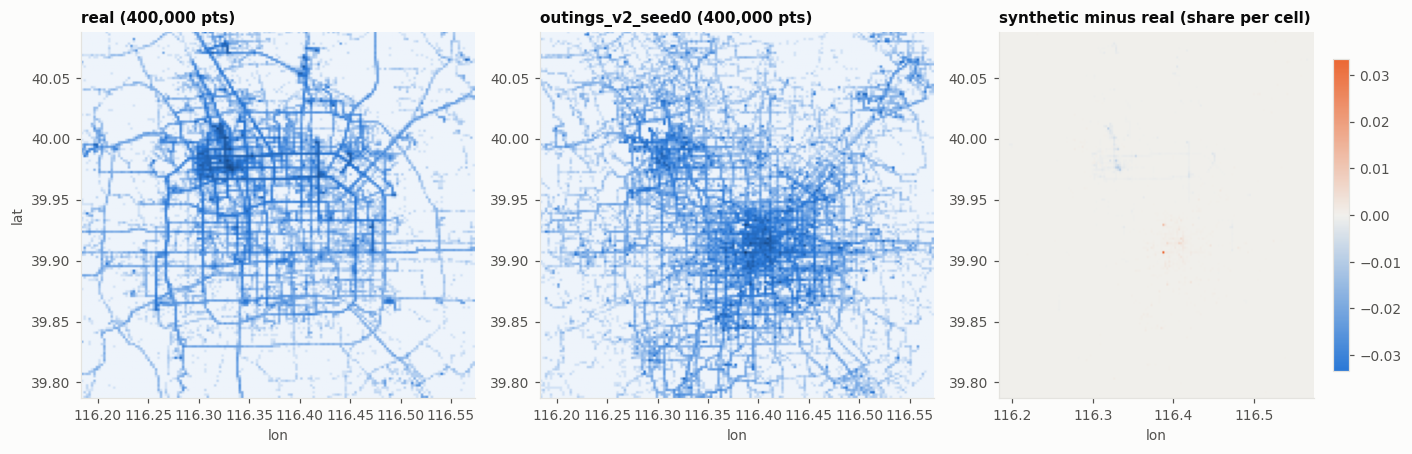

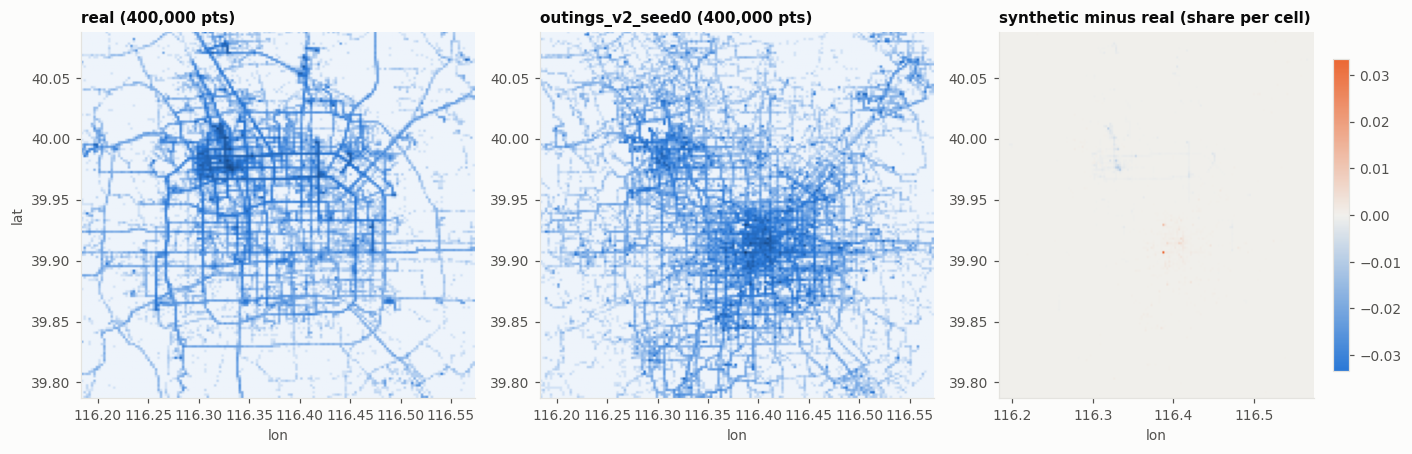

In [3]:
V.density_maps(real, syns)

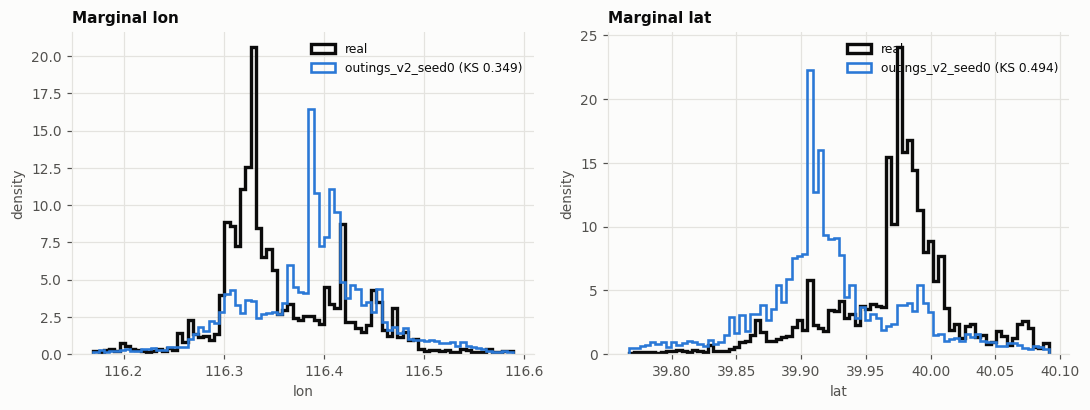

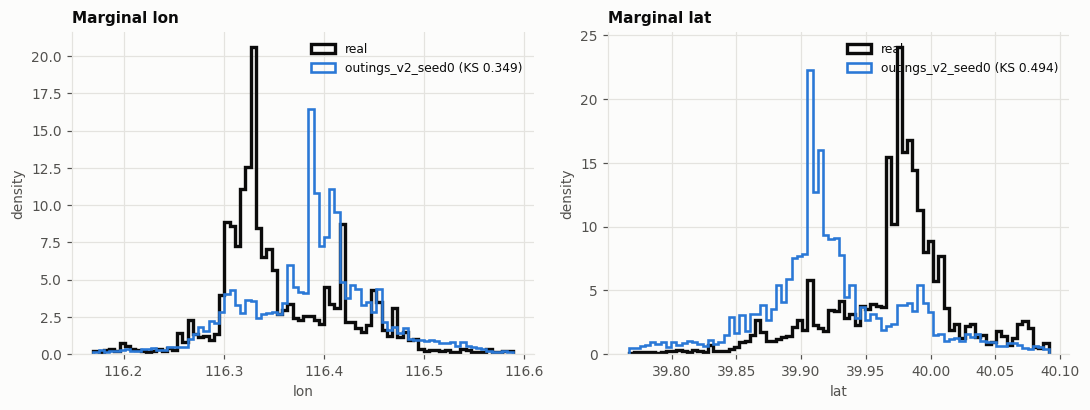

In [4]:
V.marginal_histograms(real, syns)

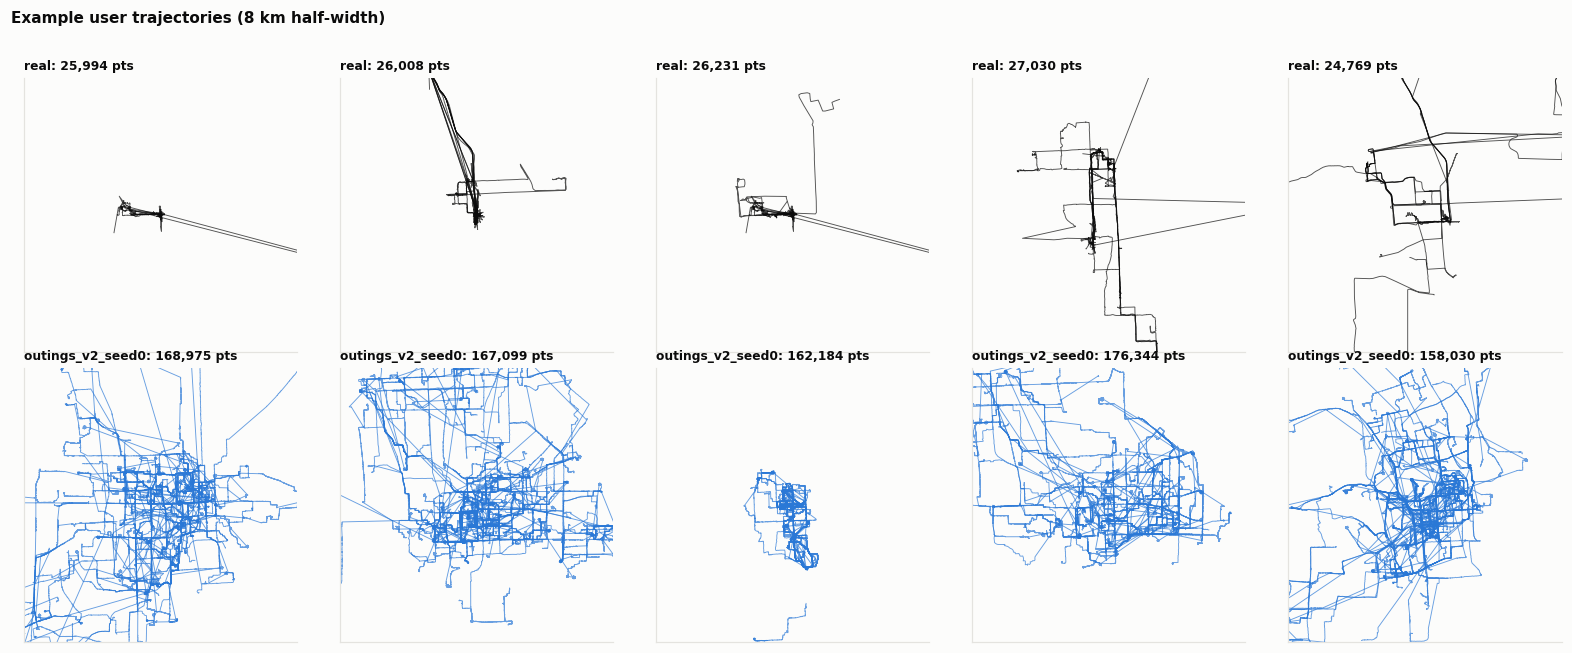

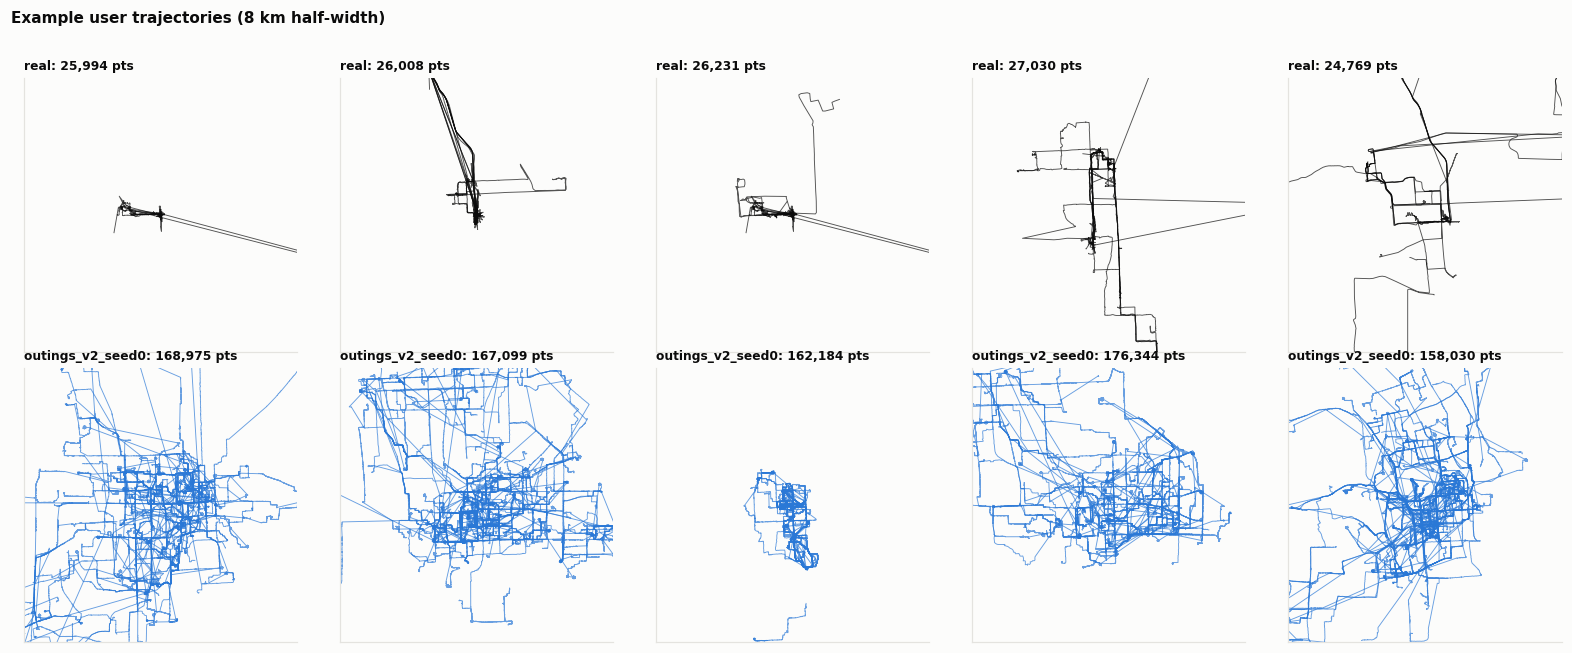

In [5]:
V.example_trajectories(real, syns, n=5)

**What we see (baseline, before sensor tables).** The synthetic mass sits on the real road network
(teleport works: same ring roads, same hub quarters), but it concentrates south-east of the real centre of
mass and spreads wider; the marginals overlap with small KS. The example traces give it away: real traces
are thin lines with sharp corners, synthetic ones are fuzzy bands - the hand-set GPS noise is large
relative to the 2 s step.

## 2. Moments and shape

ECDF overlays and QQ plots for every numeric quantity: point level (sampling interval, gap length, step
length, speed overall and by mode, heading change, positional jitter at stops), outing level (length,
duration, stops, dwell) and user level (points, outings, active days, distinct places, revisit rate).
*Look for:* bulk agreement in the ECDFs; QQ points on the diagonal (above = synthetic heavier tail).

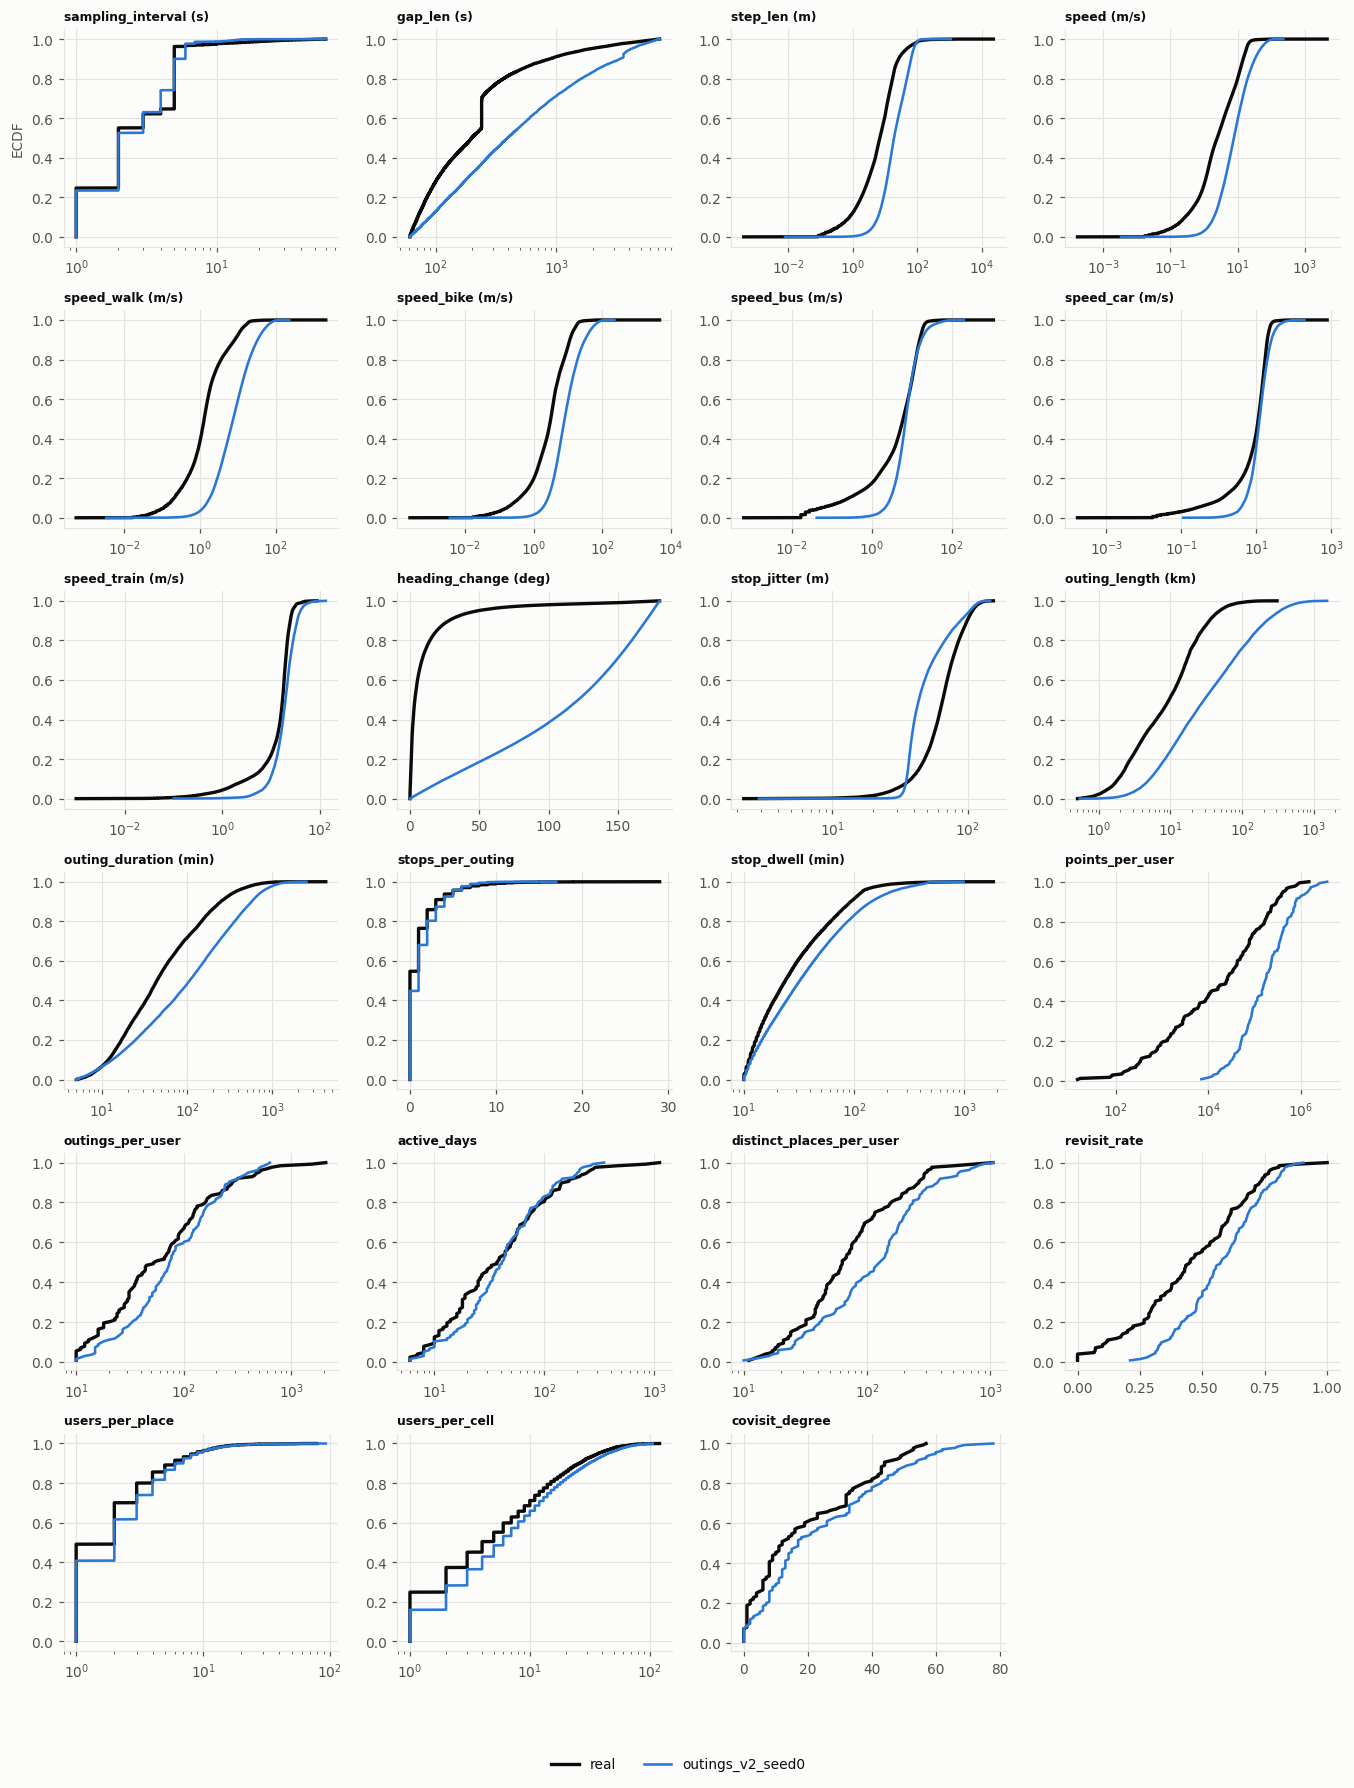

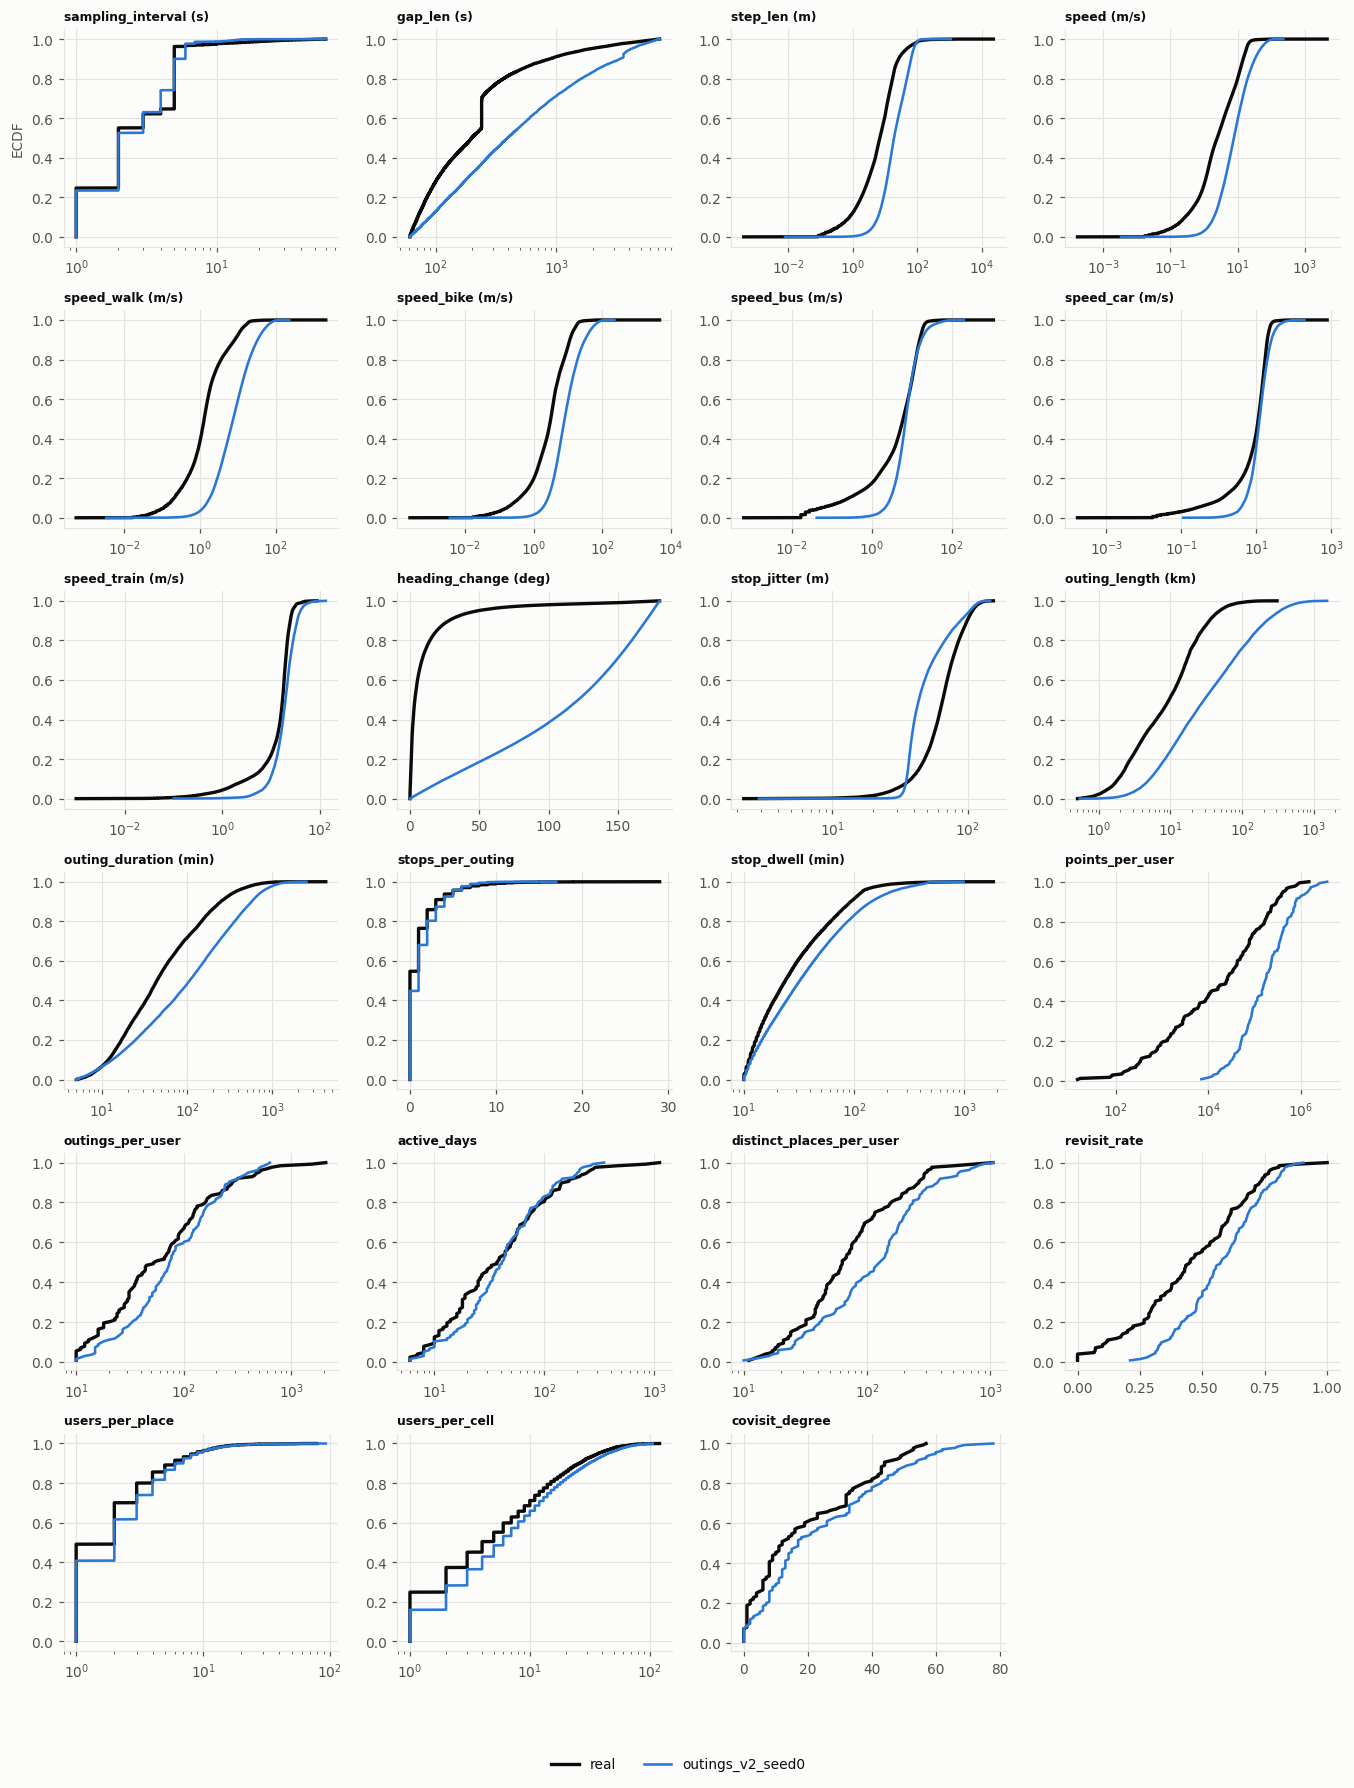

In [6]:
V.ecdf_panels(real, syns)

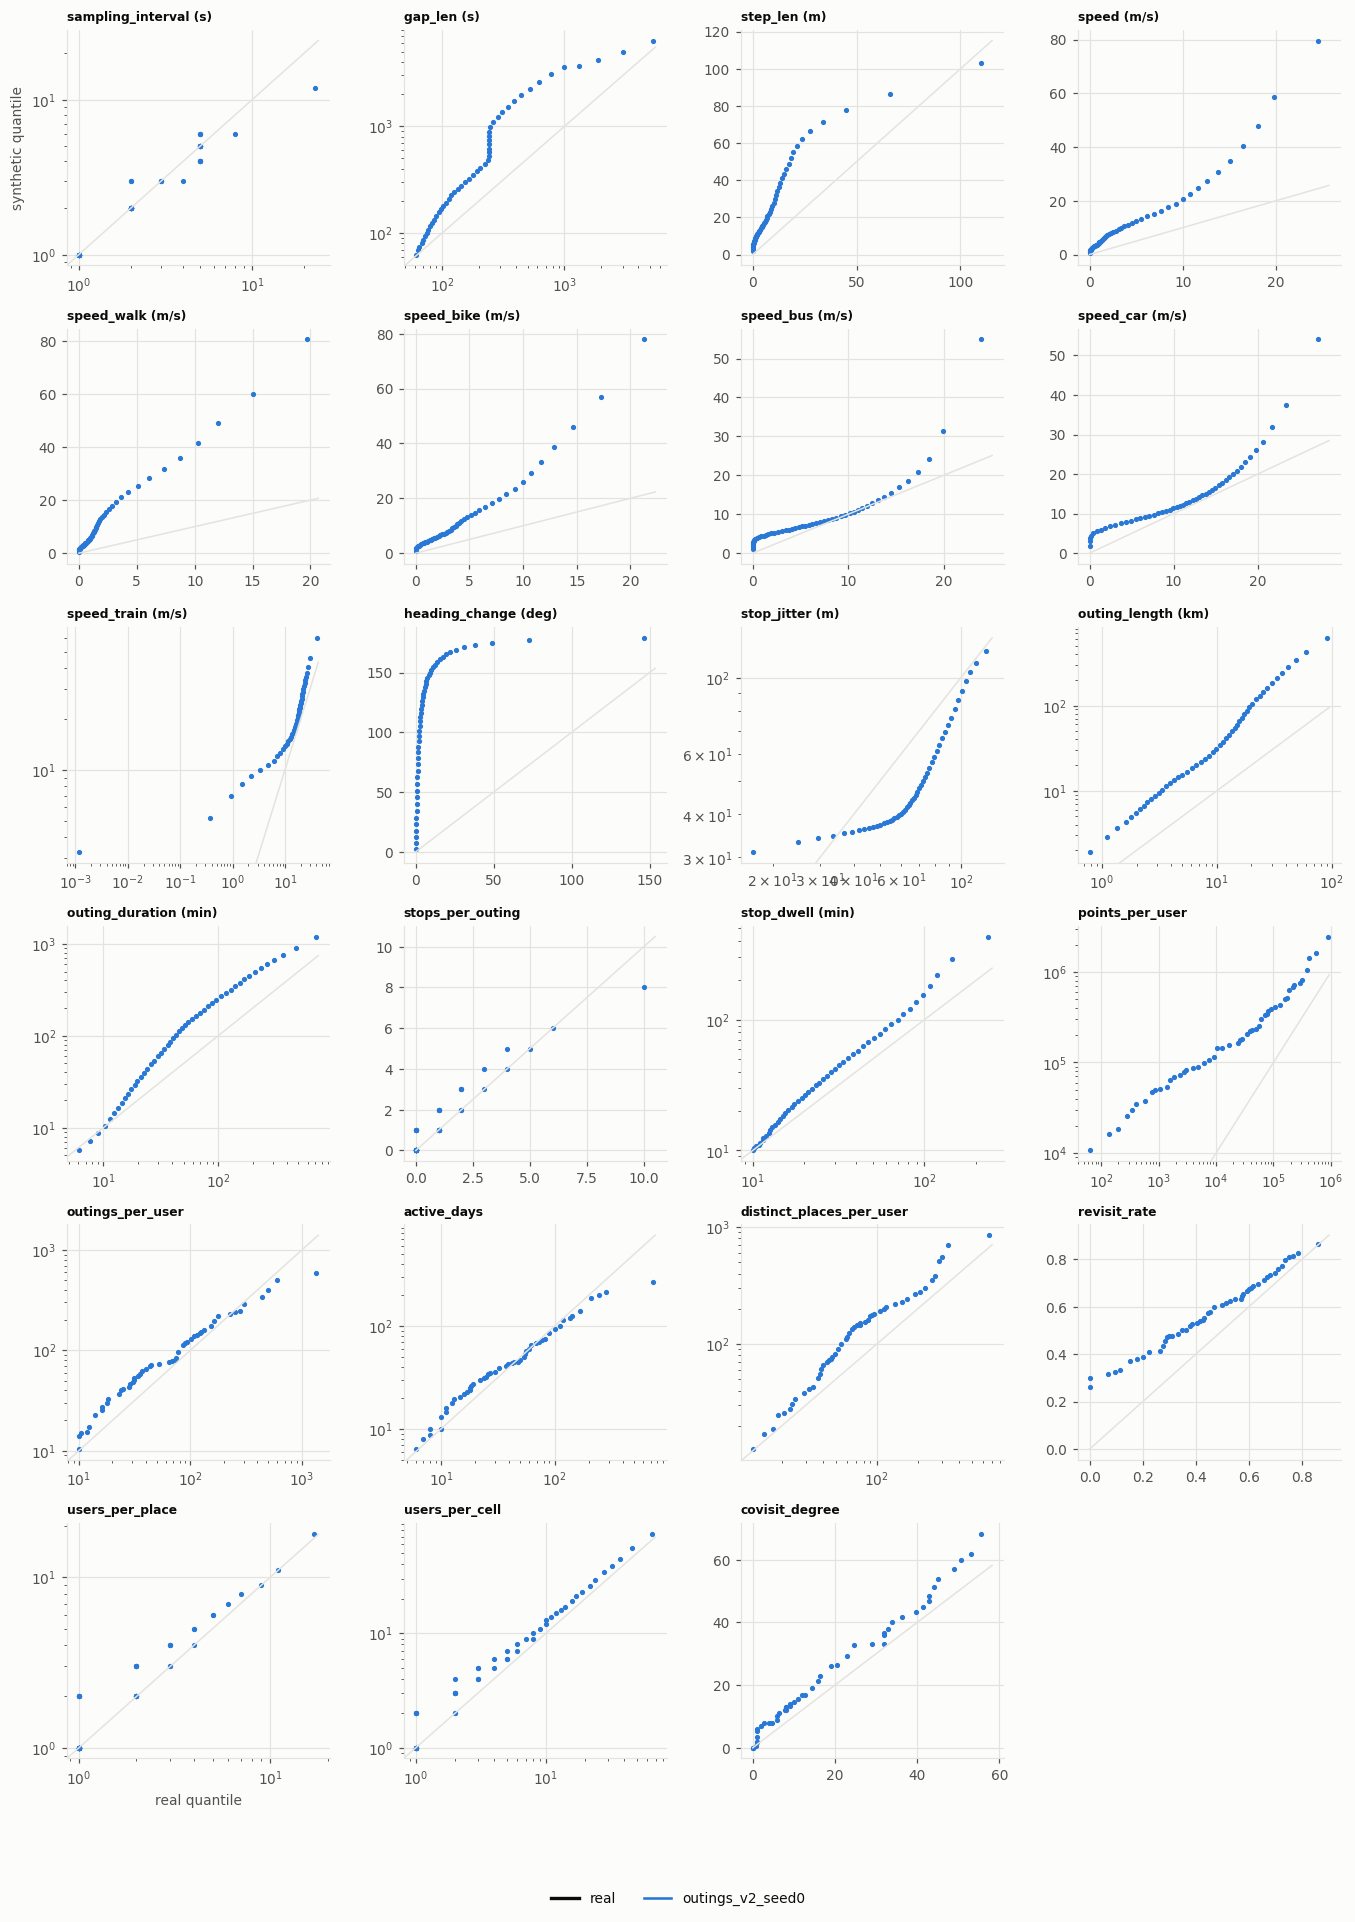

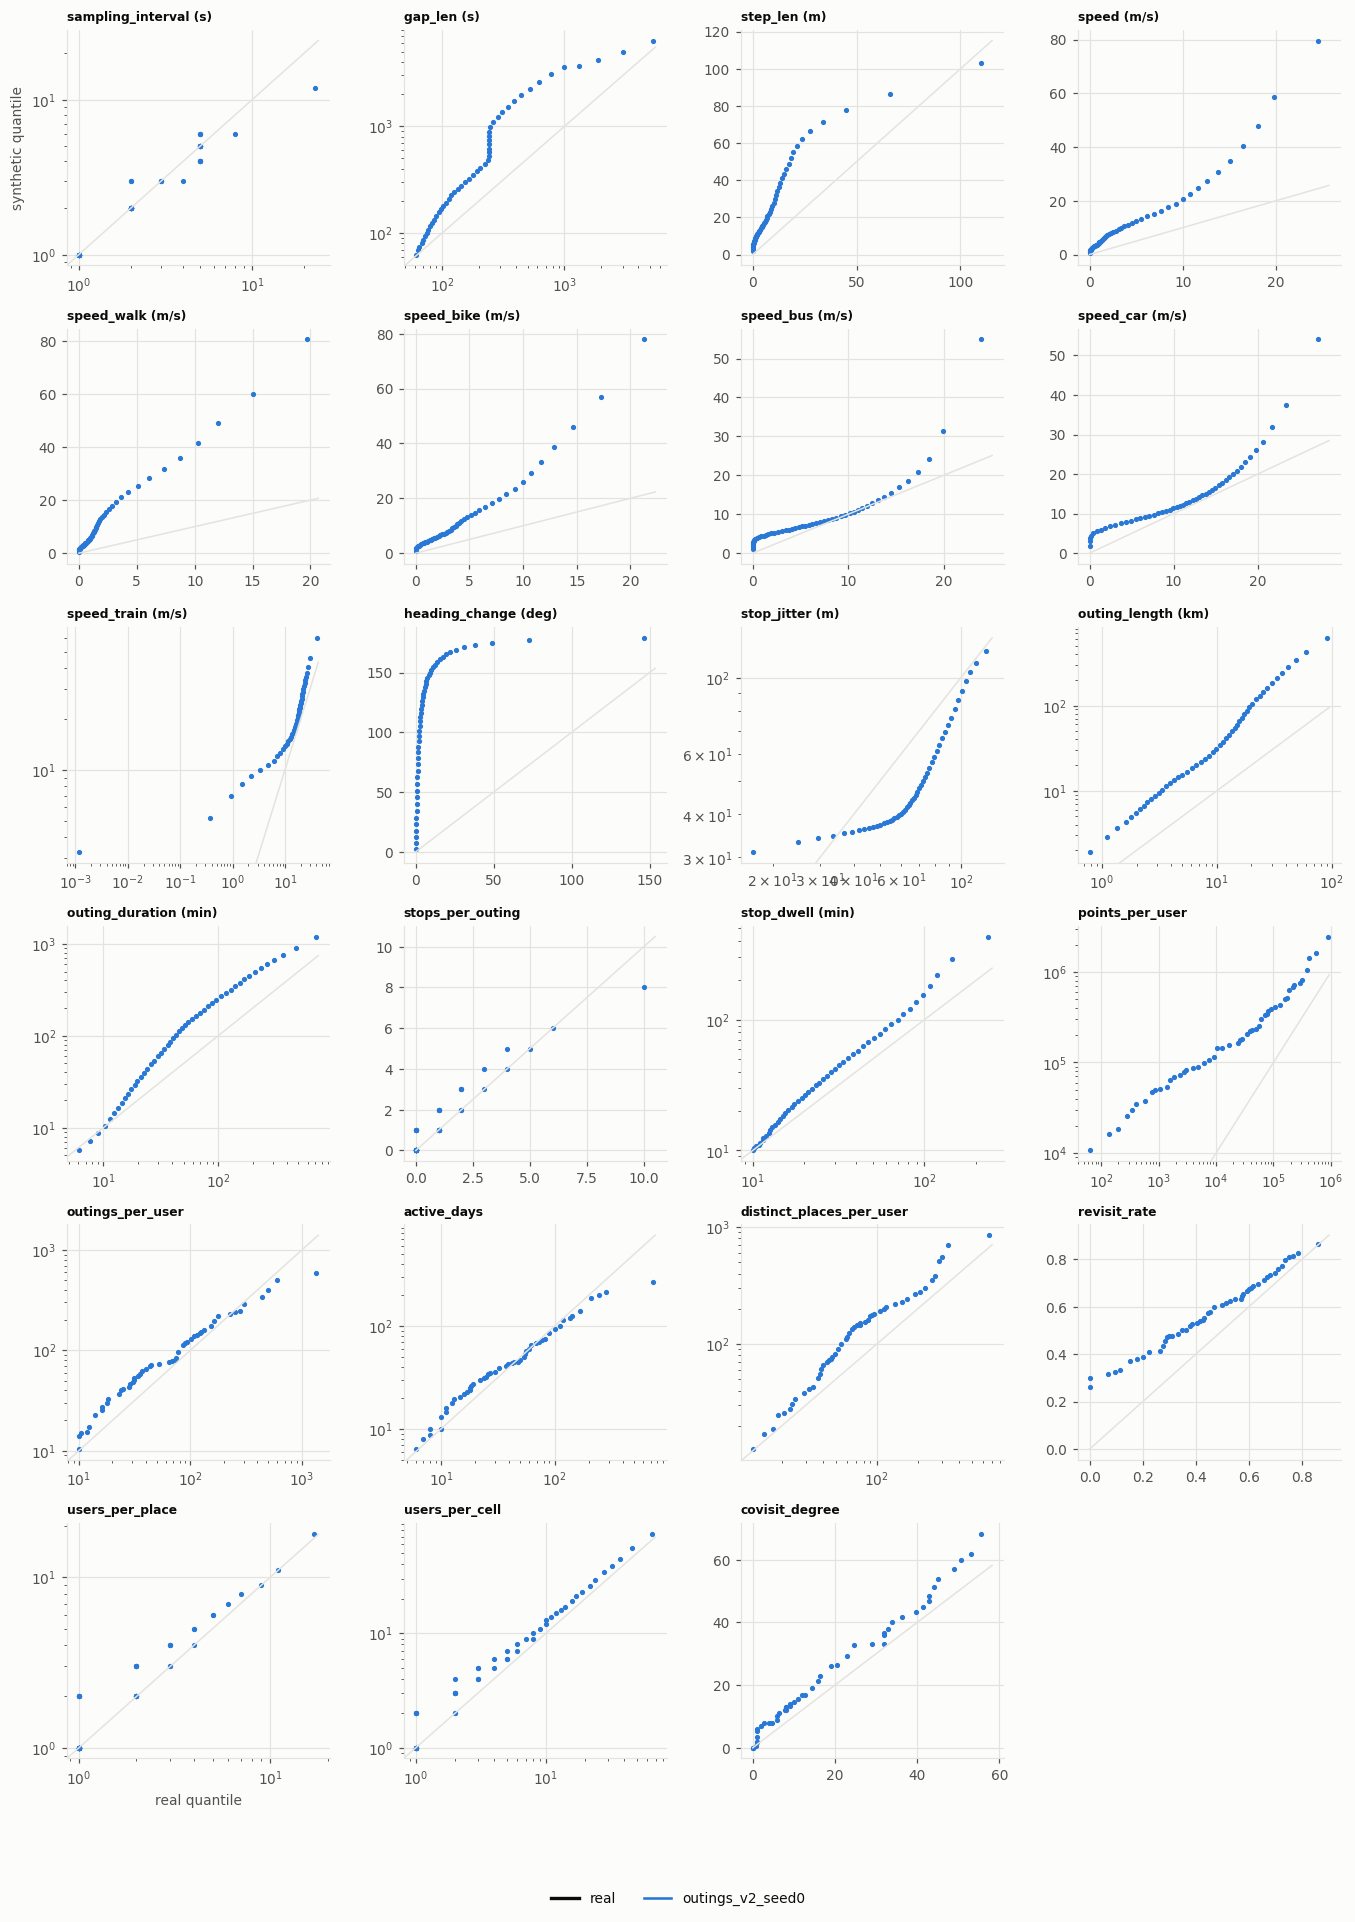

In [7]:
V.qq_panels(real, syns)

**What we see.** The biggest gaps are exactly the hand-set sensor knobs (PLAN next step 1): heading
change (real median ~4 deg, synthetic ~120 deg: noise dominates the direction signal), speeds (synthetic
"walk" at ~14 m/s because rendered speeds are too high and the mode heuristic reclassifies), step length
~2x, gaps too long and too rare, stop jitter too clean. Outing length/duration and points per user are
several times too large (generator realism, step 5). Sampling interval, stops per outing and outings per
user are already close.

## 3. Time

Hour-of-day profiles of outing starts and stops (weekday / weekend, local time) and the coarse time-bin
shares. *Look for:* the real 08h and 17-18h start peaks and the weekend skew of stops.

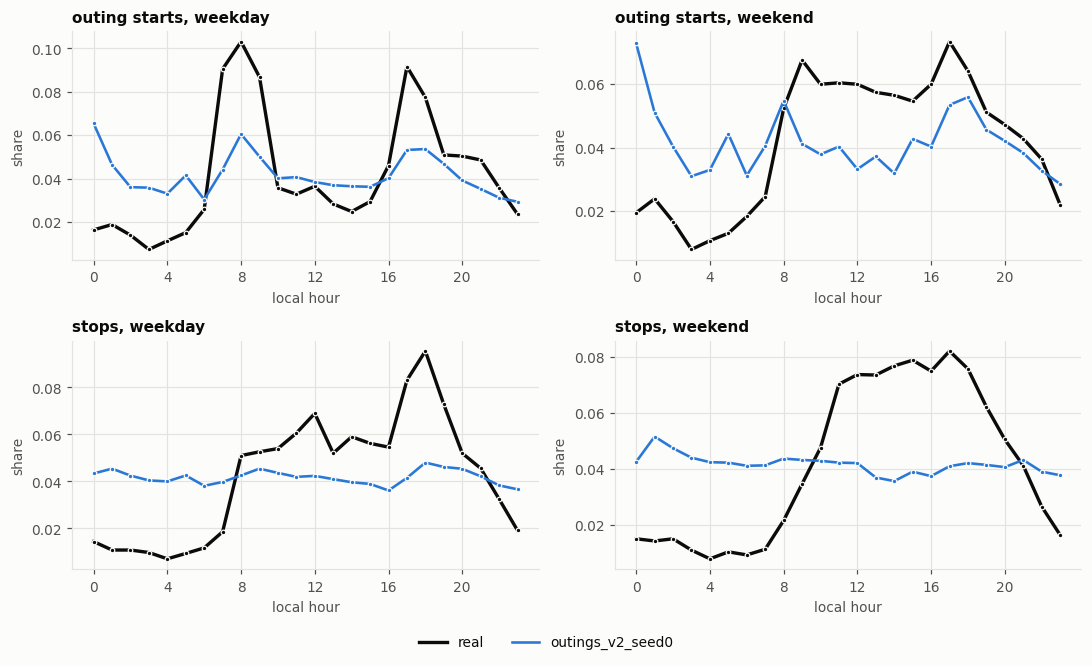

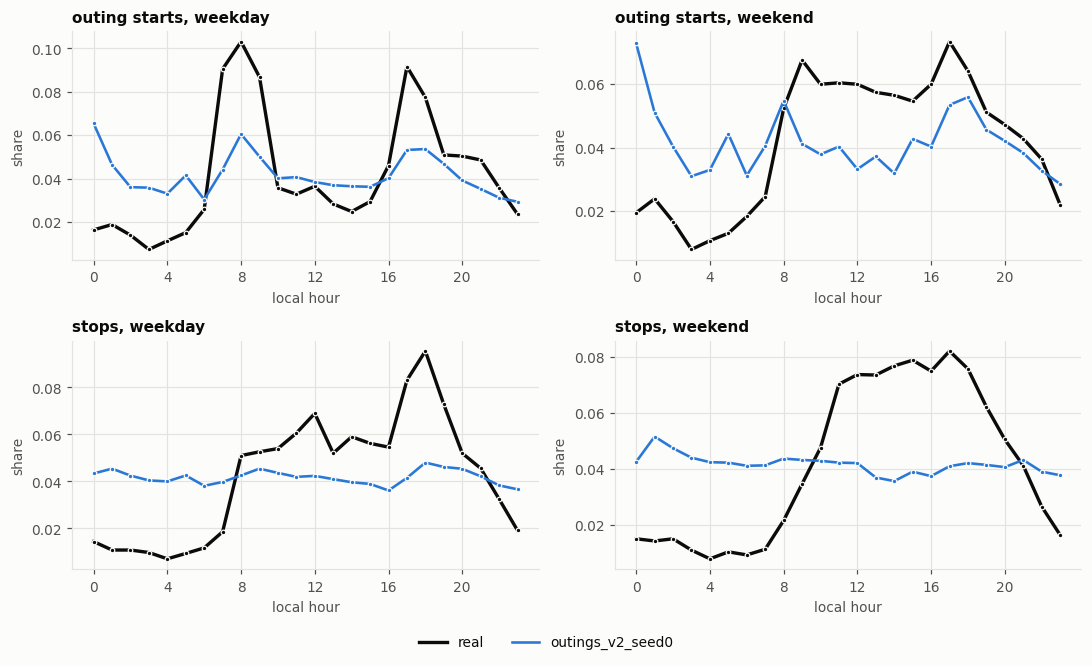

In [8]:
V.hour_profiles(real, syns)

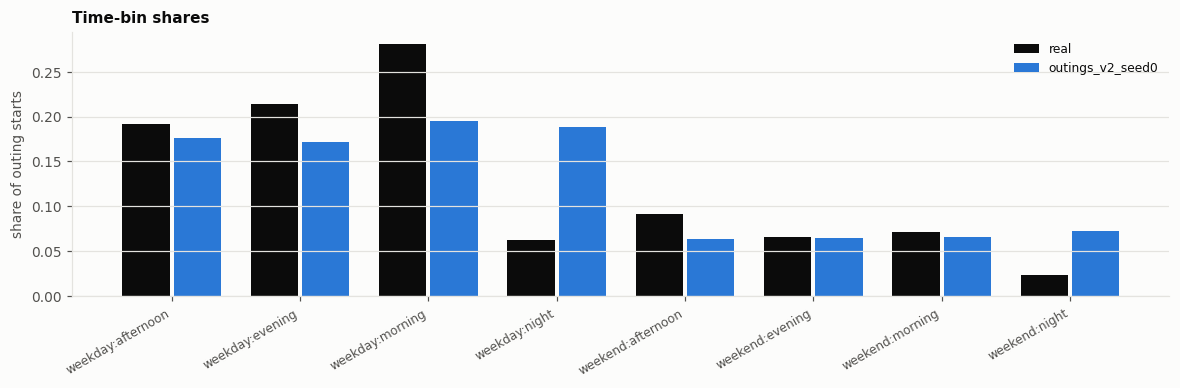

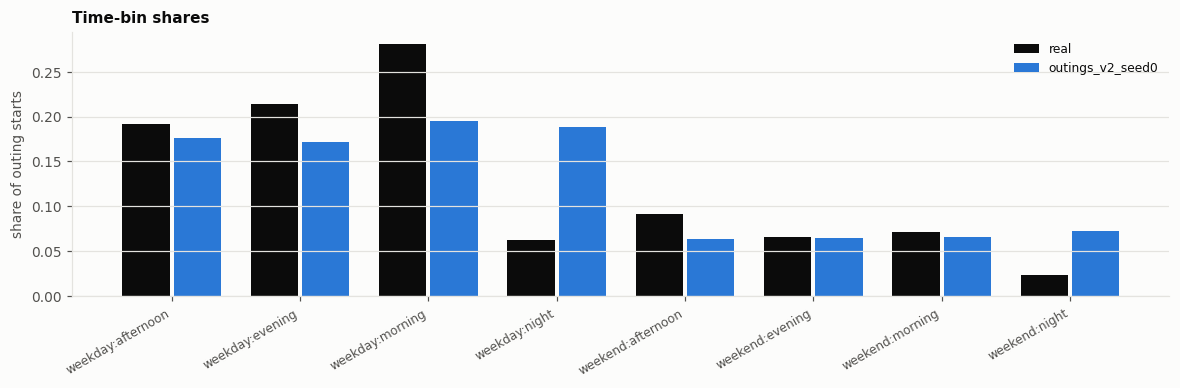

In [9]:
V.timebin_shares(real, syns)

**What we see.** The synthetic day is too flat: the sharp real 08h start peak and the 17-18h shoulder
are smeared (hour-profile TV 0.22-0.33, time-bin shares TV 0.18) - expected while the released time tables
are mostly noise at epsilon 6 (3-bin redesign is PLAN next step 2).

## 4. Social / place structure

Users per place and per traversed cell (CCDF), revisit rate per user, and the co-visit degree
distribution; then the same panels on split halves of each dataset (A solid, B dashed) - a dataset whose
halves disagree is unstable before it is wrong. *Look for:* hub places reaching tens of users in the real
curve, and the synthetic co-visit degrees not exceeding the real ones.

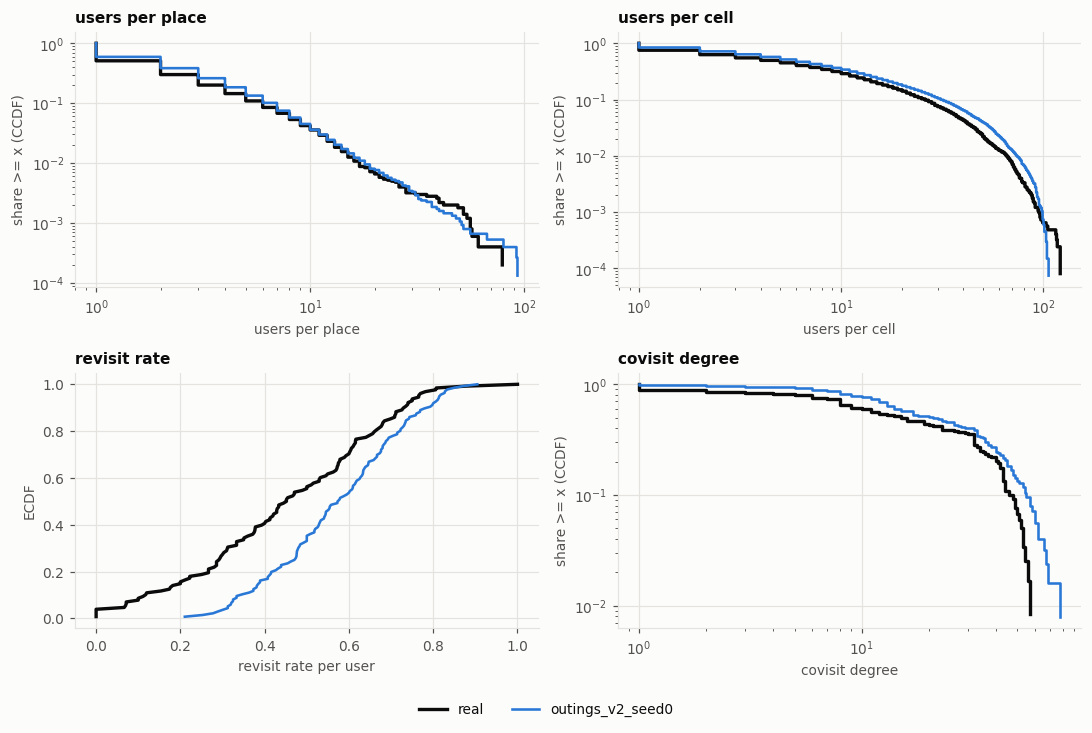

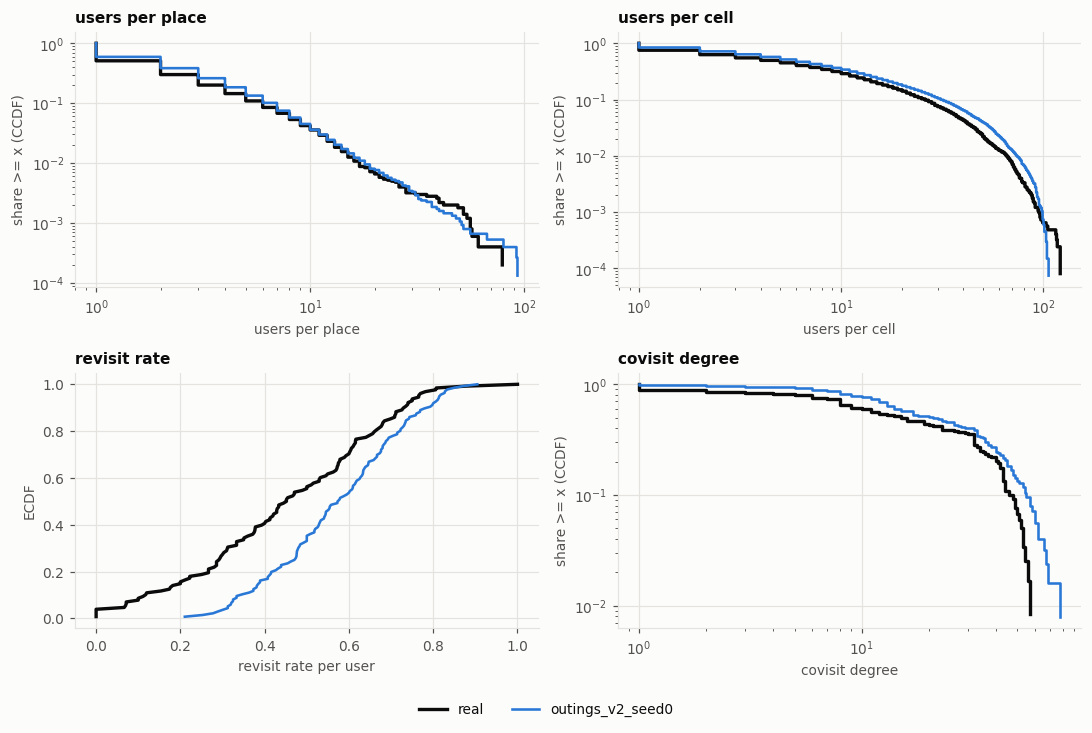

In [10]:
V.structure_panels(real, syns)

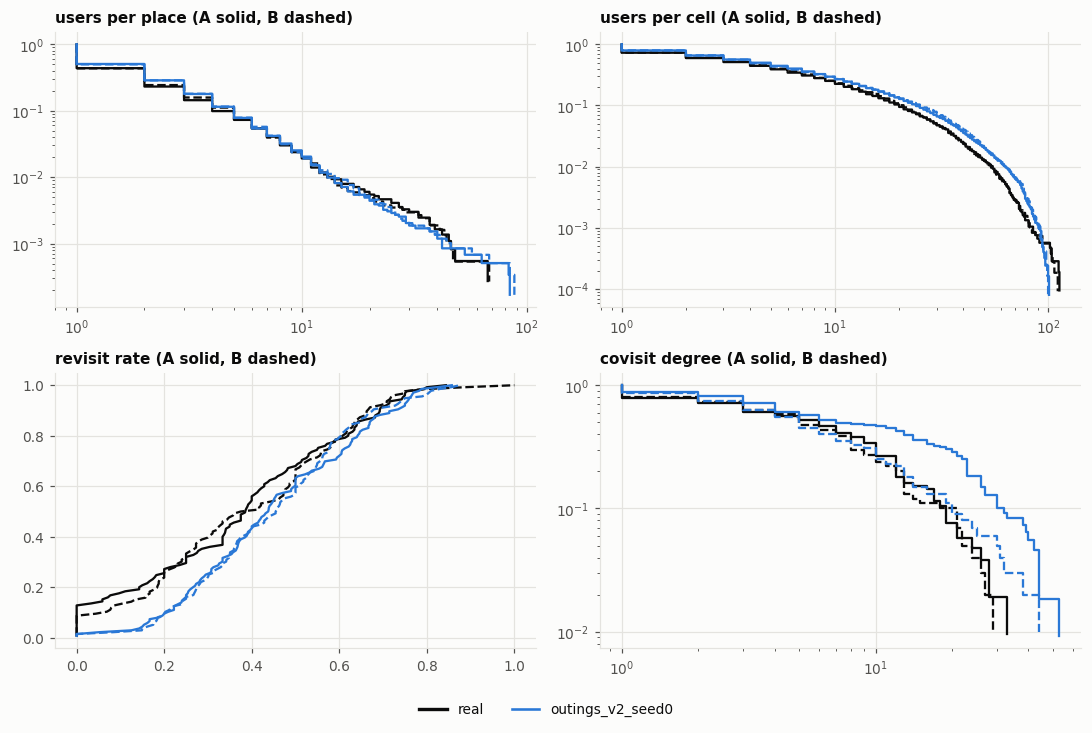

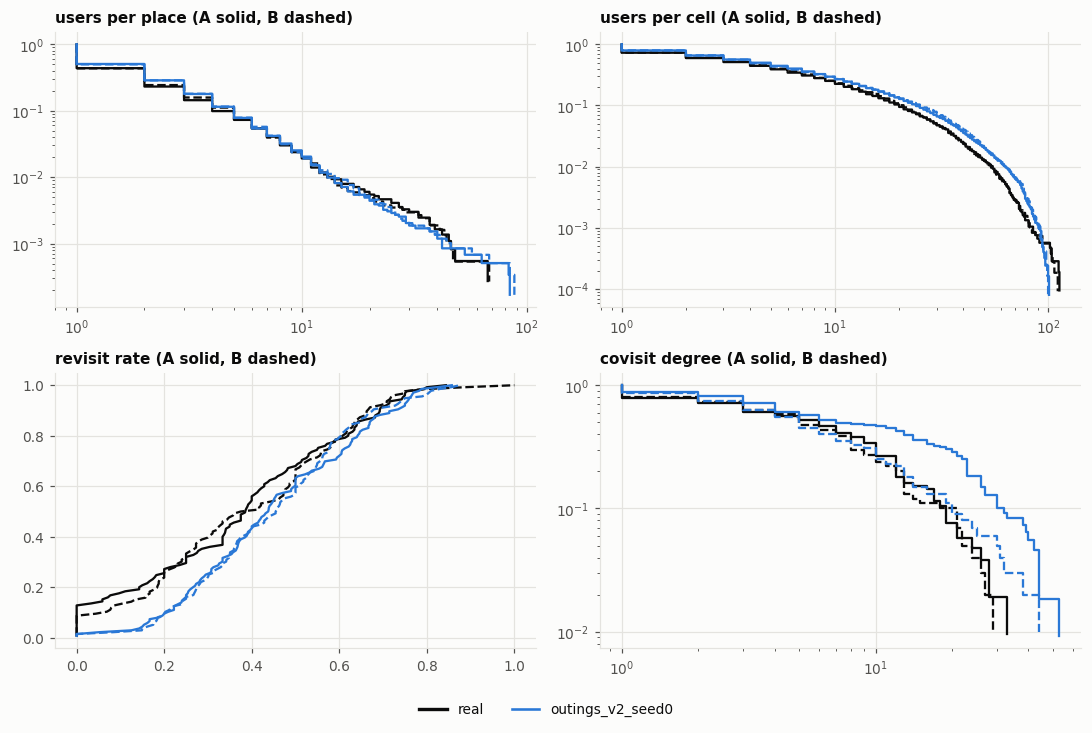

In [11]:
V.split_half_structure(real, syns)

**What we see.** Structure is the closest part of the baseline: users per place TV 0.08 and users per
cell TV 0.09 with the same power-law shape and hub tail, co-visit degree a little high (mean 24 vs 19).
Revisit rate is clearly shifted (0.57 vs 0.45, and no low-revisit users at all). The split halves agree
within each dataset, so these gaps are real, not noise.

## 5. Summary distance table

One row per quantity: moments of both sides (mean, std, skewness, kurtosis, p1..p99 in the CSV) and the
distances (KS, Wasserstein-1, total variation, relative error of moments). Written to
`geolife/eval/results/compare_<variant>.{csv,md}` so progress can be tracked run to run.

In [12]:
df = C.summary_table(real, syn)
C.write_summary(df, ROOT / "geolife" / "eval" / "results", f"compare_{Path(SYN).name}")
df[[c for c in C.MD_COLS if c in df.columns]].round(4)

,quantity,group,n_real,n_syn,real_mean,syn_mean,real_p50,syn_p50,real_p95,syn_p95,ks,wasserstein,tv,rel_err_mean,rel_err_p50
0,sampling_interval,point,1948679,2517705,3.4333,3.0921,2.0000,2.0000,5.0000,6.000000e+00,0.0937,0.5348,0.1836,0.0994,0.0000
1,gap_len,point,19095,7944,435.8478,1027.2824,199.0000,393.0000,1881.6000,4.173300e+03,0.3375,591.4364,0.3394,1.3570,0.9749
2,step_len,point,1948679,2517705,13.2668,28.3142,6.4173,19.0938,45.1482,7.766400e+01,0.4006,17.4581,0.3999,1.1342,1.9754
3,speed,point,1955426,2519161,5.0891,13.4902,2.1943,7.7188,18.0311,4.768900e+01,0.3826,8.4622,0.3823,1.6508,2.5177
4,speed_walk,point,837742,1957550,2.7915,13.6604,1.2382,7.6346,12.0458,4.897120e+01,0.5863,10.9953,0.5857,3.8936,5.1658
5,speed_bike,point,415517,442635,4.5886,13.4696,3.0242,8.0276,14.6325,4.598670e+01,0.4166,8.8731,0.4157,1.9355,1.6545
6,speed_bus,point,280043,66895,7.0161,9.6654,5.6861,7.1943,18.4419,2.424680e+01,0.2571,2.6831,0.2972,0.3776,0.2653
7,speed_car,point,221391,14148,10.7415,14.4340,10.9307,12.1070,21.7112,3.187280e+01,0.1670,3.7162,0.2127,0.3438,0.1076
8,speed_train,point,27077,3724,15.9980,21.4812,17.2358,19.8819,27.4975,4.052440e+01,0.2169,5.4832,0.2403,0.3427,0.1535
9,heading_change,point,993359,2180492,11.6325,109.1749,3.5321,121.3680,49.0771,1.751223e+02,0.7913,97.4161,0.7903,8.3853,33.3615
